# 01 — Exploratory Data Analysis

CreditShield credit-default pipeline: EDA over the raw Home Credit tables in `data/raw/`.
This runs directly against the CSVs with pandas/matplotlib/seaborn — no dbt/Postgres
required for this notebook.

Tables covered: `application_train.csv` (the main table, one row per applicant, carries
`TARGET`), plus the five satellite tables that feed the engineered feature table
(`bureau.csv`, `bureau_balance.csv`, `previous_application.csv`,
`installments_payments.csv`, `credit_card_balance.csv`, `POS_CASH_balance.csv`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
RAW = "../data/raw"


## 1. The main application table

In [2]:
app = pd.read_csv(f"{RAW}/application_train.csv")
print(f"application_train.csv: {app.shape[0]:,} rows x {app.shape[1]} columns")
app.head(3)


application_train.csv: 307,511 rows x 122 columns


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Target class balance

`TARGET = 1` means the applicant defaulted (payment difficulties). This is the
label the whole pipeline is trying to predict, and it's heavily imbalanced.

In [3]:
target_counts = app["TARGET"].value_counts().sort_index()
default_rate = app["TARGET"].mean()
print(f"Non-default (0): {target_counts[0]:,}")
print(f"Default (1):     {target_counts[1]:,}")
print(f"Default rate:    {default_rate:.4%}")
print(f"Imbalance ratio: 1 default for every {target_counts[0] / target_counts[1]:.1f} non-defaults")


Non-default (0): 282,686
Default (1):     24,825
Default rate:    8.0729%
Imbalance ratio: 1 default for every 11.4 non-defaults


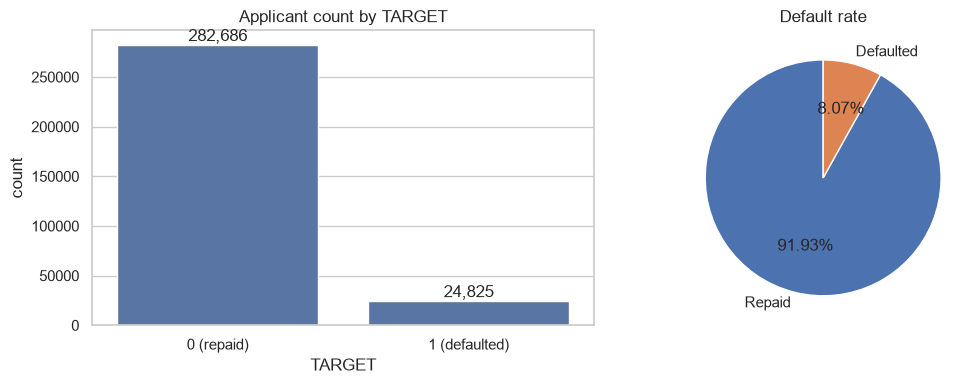

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(x="TARGET", data=app, ax=axes[0])
axes[0].set_title("Applicant count by TARGET")
axes[0].set_xticklabels(["0 (repaid)", "1 (defaulted)"])
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                      ha="center", va="bottom")

axes[1].pie([target_counts[0], target_counts[1]], labels=["Repaid", "Defaulted"],
            autopct="%1.2f%%", colors=sns.color_palette("deep", 2), startangle=90)
axes[1].set_title("Default rate")

plt.tight_layout()
plt.show()


**Reading:** the default rate is **8.07%** — roughly 1 in 12 applicants. This is
a standard class imbalance for consumer credit risk data, and it's why the pipeline's
model comparison (`experiments/run_comparison.py`) reports AUC/Gini/KS rather than raw
accuracy, and why CatBoost is trained with `auto_class_weights="Balanced"`
(see `models/train_champion.py`) instead of plain accuracy-optimized training.

## 3. Missing value patterns

Home Credit's application table has a long tail of columns with partial coverage —
mostly the `_AVG`/`_MODE`/`_MEDI` building/apartment-quality columns, plus a few
behavioral fields.

In [5]:
missing = app.isnull().sum()
missing_pct = (missing / len(app) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
print(f"{len(missing_pct)} of {app.shape[1]} columns have at least one missing value.")
missing_pct.head(20)


67 of 122 columns have at least one missing value.


COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
FLOORSMIN_MEDI              67.848630
YEARS_BUILD_AVG             66.497784
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_MEDI               59.376738
LANDAREA_AVG                59.376738
LANDAREA_MODE               59.376738
dtype: float64

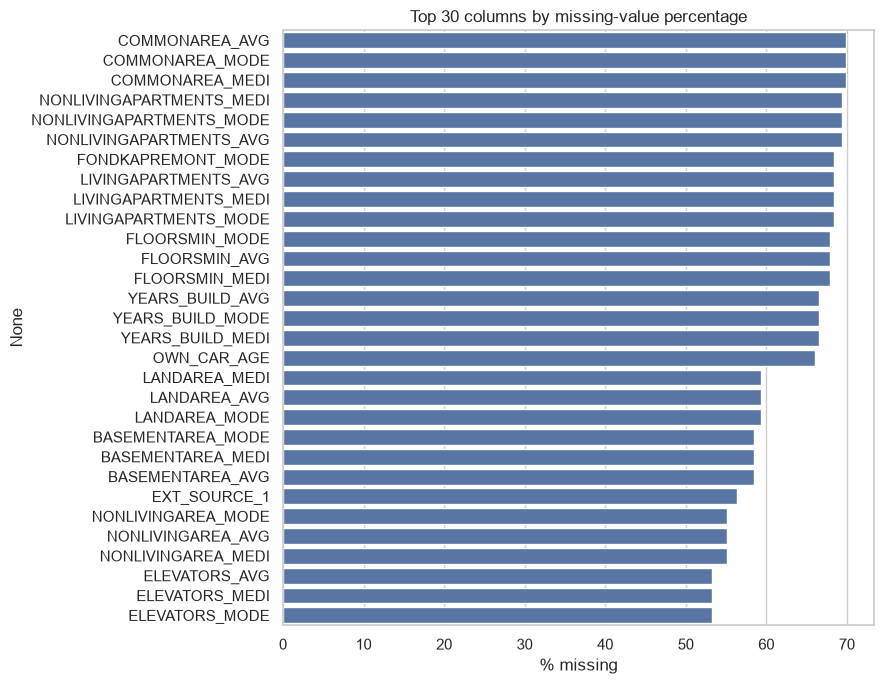

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
top30 = missing_pct.head(30)
sns.barplot(x=top30.values, y=top30.index, ax=ax, color=sns.color_palette("deep")[0])
ax.set_xlabel("% missing")
ax.set_title("Top 30 columns by missing-value percentage")
plt.tight_layout()
plt.show()


**Reading:** the worst-missing columns are almost all apartment/building-quality
descriptors (`COMMONAREA_*`, `NONLIVINGAPARTMENTS_*`, `FONDKAPREMONT_MODE`,
`LIVINGAPARTMENTS_*`) — over two-thirds missing. These aren't used by
`fct_credit_features.sql` at all (see `data_engineering/dbt_project/models/staging/stg_applications.sql`,
which selects a curated subset of columns), so this missingness doesn't propagate into
the modeling feature table. `OWN_CAR_AGE` is also heavily missing, which makes sense —
it's only defined for applicants who own a car (`FLAG_OWN_CAR = 'Y'`).

In [7]:
own_car_age_missing_given_no_car = app.loc[app["FLAG_OWN_CAR"] == "N", "OWN_CAR_AGE"].isnull().mean()
own_car_age_missing_given_car = app.loc[app["FLAG_OWN_CAR"] == "Y", "OWN_CAR_AGE"].isnull().mean()
print(f"OWN_CAR_AGE missing when FLAG_OWN_CAR == 'N': {own_car_age_missing_given_no_car:.2%}")
print(f"OWN_CAR_AGE missing when FLAG_OWN_CAR == 'Y': {own_car_age_missing_given_car:.2%}")


OWN_CAR_AGE missing when FLAG_OWN_CAR == 'N': 100.00%
OWN_CAR_AGE missing when FLAG_OWN_CAR == 'Y': 0.00%


## 4. The `DAYS_EMPLOYED` sentinel-value anomaly

`stg_applications.sql` has an explicit `CASE WHEN days_employed = 365243 THEN NULL`
rule. Let's see why.

In [8]:
print(app["DAYS_EMPLOYED"].describe())
sentinel_count = (app["DAYS_EMPLOYED"] == 365243).sum()
print(f"\nRows with DAYS_EMPLOYED == 365243: {sentinel_count:,} ({sentinel_count/len(app):.2%} of applicants)")
print(app.loc[app['DAYS_EMPLOYED'] == 365243, 'NAME_INCOME_TYPE'].value_counts())


count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

Rows with DAYS_EMPLOYED == 365243: 55,374 (18.01% of applicants)
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64


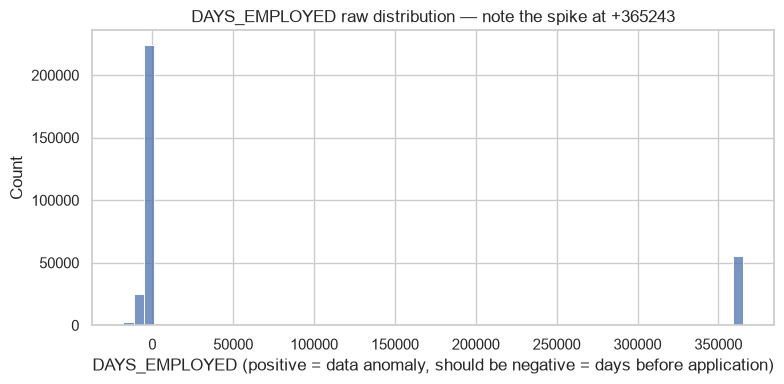

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(app["DAYS_EMPLOYED"], bins=60, ax=ax)
ax.set_title("DAYS_EMPLOYED raw distribution — note the spike at +365243")
ax.set_xlabel("DAYS_EMPLOYED (positive = data anomaly, should be negative = days before application)")
plt.tight_layout()
plt.show()


**Reading:** 365,243 days (~1000 years) is obviously not a real tenure — it's Home
Credit's placeholder for "not currently employed" (confirmed above: it's almost
entirely `Pensioner`/`Unemployed` applicants). This is exactly the same category of
issue as `03_fairness_analysis.ipynb`'s `XNA` gender finding: a placeholder value
disguised as real data, and `stg_applications.sql` correctly converts it to `NULL`
rather than treating 1000 years of tenure as a legitimate (and wildly outlying)
feature value.

## 5. Key numeric feature distributions, split by target

Income, credit amount, annuity, and age — split by repaid vs. defaulted to eyeball
which raw features carry univariate signal before any feature engineering.

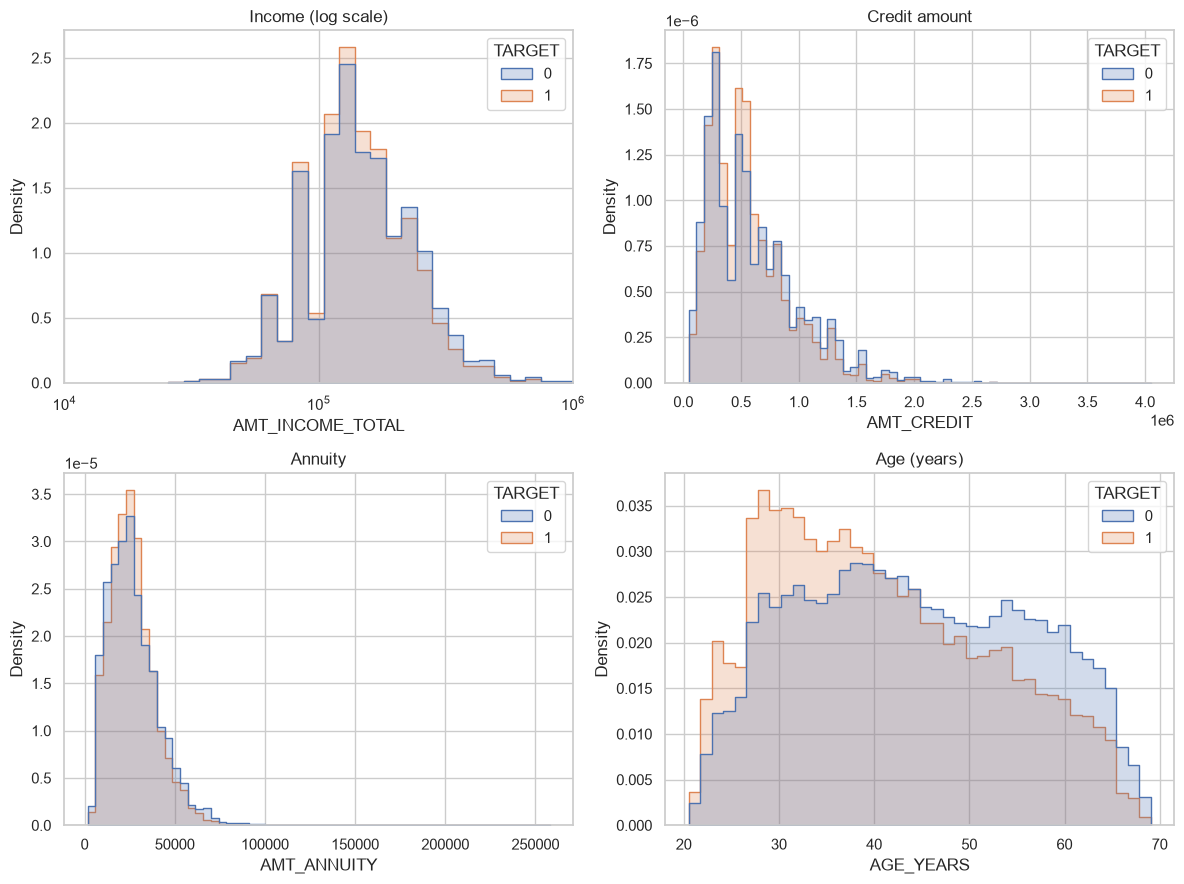

In [10]:
app["AGE_YEARS"] = app["DAYS_BIRTH"].abs() / 365.25

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(data=app, x="AMT_INCOME_TOTAL", hue="TARGET", bins=60, ax=axes[0, 0],
             log_scale=(True, False), common_norm=False, stat="density", element="step")
axes[0, 0].set_title("Income (log scale)")
axes[0, 0].set_xlim(1e4, 1e6)

sns.histplot(data=app, x="AMT_CREDIT", hue="TARGET", bins=60, ax=axes[0, 1],
             common_norm=False, stat="density", element="step")
axes[0, 1].set_title("Credit amount")

sns.histplot(data=app, x="AMT_ANNUITY", hue="TARGET", bins=60, ax=axes[1, 0],
             common_norm=False, stat="density", element="step")
axes[1, 0].set_title("Annuity")

sns.histplot(data=app, x="AGE_YEARS", hue="TARGET", bins=40, ax=axes[1, 1],
             common_norm=False, stat="density", element="step")
axes[1, 1].set_title("Age (years)")

plt.tight_layout()
plt.show()


In [11]:
for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AGE_YEARS"]:
    g = app.groupby("TARGET")[col].median()
    print(f"{col:20s} median (repaid)={g[0]:>12,.0f}  median (defaulted)={g[1]:>12,.0f}")


AMT_INCOME_TOTAL     median (repaid)=     148,500  median (defaulted)=     135,000
AMT_CREDIT           median (repaid)=     517,788  median (defaulted)=     497,520
AMT_ANNUITY          median (repaid)=      24,876  median (defaulted)=      25,263


AGE_YEARS            median (repaid)=          43  median (defaulted)=          39


**Reading:** defaulters skew younger (lower median age) and toward slightly lower
income and credit amounts. This is the same pattern the fairness audit in
`03_fairness_analysis.ipynb` investigates in depth — the model correlates age with
risk, which is exactly why age ends up as a protected-attribute fairness concern
rather than just an engineering curiosity.

## 6. Categorical breakdowns vs. target

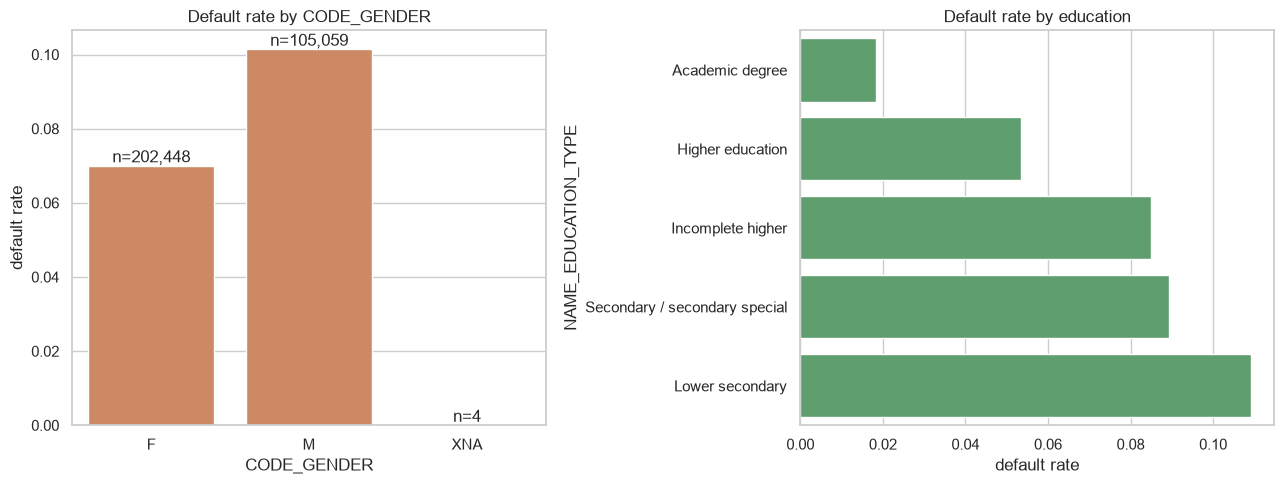

                 mean   count
CODE_GENDER                  
F            0.069993  202448
M            0.101419  105059
XNA          0.000000       4


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

gender_rate = app.groupby("CODE_GENDER")["TARGET"].agg(["mean", "count"])
sns.barplot(x=gender_rate.index, y=gender_rate["mean"], ax=axes[0], color=sns.color_palette("deep")[1])
axes[0].set_title("Default rate by CODE_GENDER")
axes[0].set_ylabel("default rate")
for i, (idx, row) in enumerate(gender_rate.iterrows()):
    axes[0].annotate(f"n={int(row['count']):,}", (i, row["mean"]), ha="center", va="bottom")

edu_rate = app.groupby("NAME_EDUCATION_TYPE")["TARGET"].mean().sort_values()
sns.barplot(x=edu_rate.values, y=edu_rate.index, ax=axes[1], color=sns.color_palette("deep")[2])
axes[1].set_title("Default rate by education")
axes[1].set_xlabel("default rate")

plt.tight_layout()
plt.show()
print(gender_rate)


**Reading:** `CODE_GENDER` includes an `XNA` category (4 rows, Home Credit's
placeholder for undisclosed gender — not a real third demographic group) — this shows
up here as a tiny bar and is the exact issue `03_fairness_analysis.ipynb`'s Stage 11
finding investigates in depth (including it in a fairness metric swings the
demographic-parity gap by 6.6x from 4 rows out of 307,511). Education shows a clear
monotonic pattern: higher education correlates with lower default rate, an intuitive
and stable relationship.

## 7. The satellite tables

Quick shape/coverage check on the other five raw tables that feed the engineered
feature table (`fct_credit_features.sql`), without loading the largest ones fully
into memory — `bureau_balance.csv` (27M rows) and `POS_CASH_balance.csv` (10M rows)
are read with `usecols` only.

In [13]:
import os

satellite_info = []
for fname, id_col in [
    ("bureau.csv", "SK_ID_CURR"),
    ("bureau_balance.csv", "SK_ID_BUREAU"),
    ("previous_application.csv", "SK_ID_CURR"),
    ("installments_payments.csv", "SK_ID_CURR"),
    ("credit_card_balance.csv", "SK_ID_CURR"),
    ("POS_CASH_balance.csv", "SK_ID_CURR"),
]:
    path = f"{RAW}/{fname}"
    ids = pd.read_csv(path, usecols=[id_col])[id_col]
    satellite_info.append({
        "table": fname,
        "rows": len(ids),
        "distinct_ids": ids.nunique(),
        "size_mb": os.path.getsize(path) / 1e6,
    })

satellite_df = pd.DataFrame(satellite_info)
satellite_df


,table,rows,distinct_ids,size_mb
0,bureau.csv,1716428,305811,170.016717
1,bureau_balance.csv,27299925,817395,375.592889
2,previous_application.csv,1670214,338857,404.973293
3,installments_payments.csv,13605401,339587,723.118349
4,credit_card_balance.csv,3840312,103558,424.582605
5,POS_CASH_balance.csv,10001358,337252,392.703158


In [14]:
bureau = pd.read_csv(f"{RAW}/bureau.csv")
apps_with_bureau_history = bureau["SK_ID_CURR"].nunique()
print(f"{apps_with_bureau_history:,} of {app.shape[0]:,} applicants "
      f"({apps_with_bureau_history/app.shape[0]:.1%}) have at least one prior bureau-reported loan")
print(f"\nbureau.csv rows per applicant (distribution):")
print(bureau.groupby("SK_ID_CURR").size().describe())
del bureau


305,811 of 307,511 applicants (99.4%) have at least one prior bureau-reported loan

bureau.csv rows per applicant (distribution):


count    305811.000000
mean          5.612709
std           4.430354
min           1.000000
25%           2.000000
50%           4.000000
75%           8.000000
max         116.000000
dtype: float64


**Reading:** `bureau.csv` covers most, not all, applicants — the rest have no
external credit-bureau history at all, which is exactly why `fct_credit_features.sql`
does a `LEFT JOIN` from the application table (not an inner join) and `COALESCE`s
every bureau-derived feature to 0 for applicants with no bureau rows. The same pattern
holds for the other four satellite tables — this is why `02_feature_analysis.ipynb`'s
pandas re-implementation of the dbt joins also needs to be `LEFT JOIN` + fill, not an
inner join, or it would silently drop every applicant without prior credit history.

## 8. Summary

- **Target imbalance:** 8.07% default rate (24,825 of 307,511 applicants) — informs
  the `auto_class_weights="Balanced"` choice in `models/train_champion.py` and the
  AUC/Gini/KS-based model comparison in `experiments/run_comparison.py`.
- **Missingness** is concentrated in apartment/building-quality columns not used by
  the feature table, plus the expected structural missingness in `OWN_CAR_AGE`
  (only defined for car owners).
- **`DAYS_EMPLOYED` has a placeholder sentinel value** (365243, ~55k rows, almost
  entirely pensioners/unemployed) that `stg_applications.sql` correctly nulls out —
  the same "placeholder-disguised-as-data" pattern as the `CODE_GENDER == 'XNA'`
  issue investigated in `03_fairness_analysis.ipynb`.
- **Age and income/credit amount separate repaid vs. defaulted applicants** at the
  univariate level, which is the root of the age-fairness investigation in notebook 03.
- **Satellite tables have partial coverage** of the applicant population, which is
  why every join in `fct_credit_features.sql` is a `LEFT JOIN` with `COALESCE`-to-0,
  not an inner join.